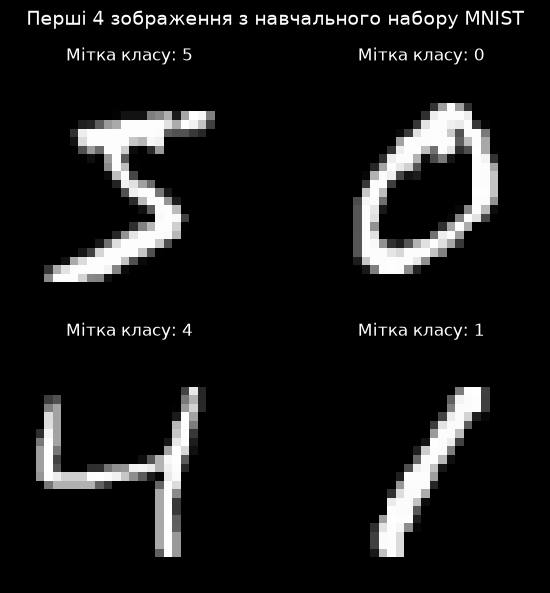

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers, models
from keras.utils import to_categorical

os.makedirs('models', exist_ok=True)
np.random.seed(42)
tf.random.set_seed(42)

(X_train_raw, y_train_raw), (X_test_raw, y_test_raw) = keras.datasets.mnist.load_data()

plt.figure(figsize=(6, 6))
for i in range(4):
    plt.subplot(2, 2, i + 1)
    plt.imshow(X_train_raw[i], cmap='gray')
    plt.title(f"Мітка класу: {y_train_raw[i]}")
    plt.axis('off')
plt.suptitle("Перші 4 зображення з навчального набору MNIST", fontsize=14)
plt.tight_layout()
plt.show()


In [2]:
num_pixels = 28 * 28
X_train_mlp = X_train_raw.reshape((X_train_raw.shape[0], num_pixels)).astype('float32') / 255.0
X_test_mlp = X_test_raw.reshape((X_test_raw.shape[0], num_pixels)).astype('float32') / 255.0

y_train_cat = to_categorical(y_train_raw, num_classes=10)
y_test_cat = to_categorical(y_test_raw, num_classes=10)

print(f"Форма X_train_mlp: {X_train_mlp.shape}")
print(f"Форма y_train_cat: {y_train_cat.shape}")
print(f"Форма X_test_mlp: {X_test_mlp.shape}")


Форма X_train_mlp: (60000, 784)
Форма y_train_cat: (60000, 10)
Форма X_test_mlp: (10000, 784)


In [3]:
def baseline_mlp():
    model = models.Sequential([
        layers.Input(shape=(num_pixels,)),
        layers.Dense(num_pixels, activation='relu'),
        layers.Dense(10, activation='softmax')
    ])
    model.compile(
        loss='categorical_crossentropy',
        optimizer='adam',
        metrics=['accuracy']
    )
    return model

model_mlp = baseline_mlp()
model_mlp.summary()

history_mlp = model_mlp.fit(
    X_train_mlp, 
    y_train_cat, 
    validation_data=(X_test_mlp, y_test_cat), 
    epochs=10, 
    batch_size=200, 
    verbose=1
)

scores = model_mlp.evaluate(X_test_mlp, y_test_cat, verbose=0)
accuracy = scores[1] * 100
error_rate = 100 - accuracy

print(f"\nТочність MLP на тесті: {accuracy:.2f}%")
print(f"Показник помилки класифікації: {error_rate:.2f}%")

mlp_path = 'models/mlp_mnist.keras'
model_mlp.save(mlp_path)
print(f"Модель збережено у: {mlp_path}")


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 784)            │       615,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 623,290 (2.38 MB)

 Trainable params: 623,290 (2.38 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9211 - loss: 0.2783 - val_accuracy: 0.9593 - val_loss: 0.1367
Epoch 2/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9685 - loss: 0.1109 - val_accuracy: 0.9708 - val_loss: 0.0987
Epoch 3/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9797 - loss: 0.0706 - val_accuracy: 0.9742 - val_loss: 0.0834
Epoch 4/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9870 - loss: 0.0484 - val_accuracy: 0.9763 - val_loss: 0.0768
Epoch 5/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9916 - loss: 0.0344 - val_accuracy: 0.9784 - val_loss: 0.0721
Epoch 6/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9948 - loss: 0.0249 - val_accuracy: 0.9800 - val_loss: 0.0679
Epoch 7/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9966 - loss: 0.0182 - val_accuracy: 0.9807 - val_loss: 0.0661
Epoch 8/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9975 - loss: 0.0141 - val_accuracy: 0.

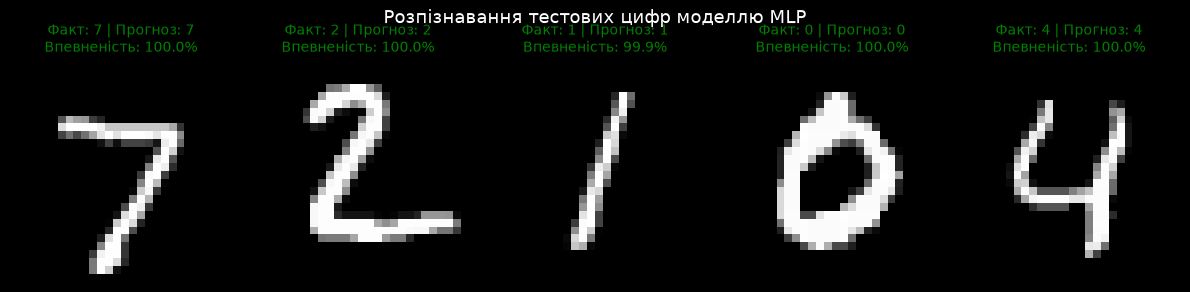

In [4]:
sample_indices = [0, 1, 2, 3, 4]
predictions = model_mlp.predict(X_test_mlp[sample_indices], verbose=0)

plt.figure(figsize=(12, 3))
for i, idx in enumerate(sample_indices):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_test_raw[idx], cmap='gray')
    pred_label = np.argmax(predictions[i])
    true_label = y_test_raw[idx]
    conf = np.max(predictions[i]) * 100
    color = 'green' if pred_label == true_label else 'red'
    plt.title(f"Факт: {true_label} | Прогноз: {pred_label}\nВпевненість: {conf:.1f}%", color=color, fontsize=10)
    plt.axis('off')
plt.suptitle("Розпізнавання тестових цифр моделлю MLP", fontsize=13)
plt.tight_layout()
plt.show()
